# Feeder-cam visit log

<a href="https://colab.research.google.com/github/sixhobbits/colab-demo/blob/main/cookbooks/feeder_watch/feeder_watch.ipynb" target="_blank"><img src="https://img.shields.io/badge/Open%20in%20Colab-F9AB00?style=for-the-badge&logo=googlecolab&logoColor=white" alt="Open in Colab" height="28"></a> <a href="https://github.com/sixhobbits/colab-demo/blob/main/cookbooks/feeder_watch/feeder_watch.ipynb" target="_blank"><img src="https://img.shields.io/badge/View%20on%20GitHub-24292F?style=for-the-badge&logo=github&logoColor=white" alt="View on GitHub" height="28"></a>

> **No API key needed.** The code downloads this cookbook's saved answers, so
> *Run all* replays every TypeSafe call from them. It needs no TypeSafe account
> and costs nothing. To call the API yourself, set `TYPESAFE_API_KEY` and
> `DOWNLOAD_CACHE = False`.

From [the docs page](https://console.typesafe.ai/docs/cookbooks/feeder_watch).

A camera on a bird feeder, a front door, or a street records hours of footage. Jev can
help you analyse it.

Send Jev the frames of a video one at a time and ask questions about each frame. With
footage from a bird feeder camera, the answers become a visit log per species.

![A snowy bird feeder with a male cardinal and a downy woodpecker, each in its own
labeled box with a species probability. A status bar shows the time, the bird_present
probability, and the visits open so far.](https://raw.githubusercontent.com/sixhobbits/colab-demo/main/cookbooks/feeder_watch/feeder-watch-hero.webp)

We send Jev one frame a second, with five questions about each frame per request:

- `bird_present`, a `Noul`: is there a bird?
- `how_many`, a `Choice` of none, one, or several
- `bird`, a `Box`: where is the most prominent bird?
- `species_left` and `species_right`, two `Choice` questions over a list of species: what
  are the leftmost and rightmost birds?

A [Box](/primitives/box) question is used to find where the bird is in the image. It
returns one box, so when two species share the feeder, a second request asks for a box
around each species by name. This cookbook boxes up to two species at a time. Plain code
turns the answers into visits.

On the 101-second video clip we used, Jev agreed with our hand labels on whether a bird
was there in all 101 frames, and named the correct species in 132 of 133 labeled bird
sightings.

> **Note** - Images and Box questions are experimental ("dreamer-ready"). Every request
> that carries an image or a Box question needs the `TypeSafe-Danger-Zone-Images: true`
> header. See [Images](/images) and [Box](/primitives/box).

## Setup

Requires Python 3.10 or later. Choose a package manager to install the dependencies:

<Tabs sync={false}>
  <Tab title="pip">
    Create a virtual environment and add the dependencies:

    ```bash wrap
    python3 -m venv .venv
    .venv/bin/pip install 'typesafe-sdk>=0.7.5,<0.8.0' pillow matplotlib ipython 'cooksafe>=0.3.0,<0.4.0'
    ```
  </Tab>
  <Tab title="uv">
    Initialize a project and add the dependencies:

    ```bash wrap
    uv init --bare
    uv add 'typesafe-sdk>=0.7.5,<0.8.0' pillow matplotlib ipython 'cooksafe>=0.3.0,<0.4.0'
    ```
  </Tab>
</Tabs>

Set your TypeSafe API key:

```bash
export TYPESAFE_API_KEY="your-api-key"
```

Create a new file named `feeder_watch.py`. As you work through this cookbook, copy each
Python code block into that file, in order. This command runs it whether you installed
with pip or uv:

```bash
.venv/bin/python feeder_watch.py
```

A full run sends about 180 requests. Pillow draws the boxes and matplotlib lays out the
figures.

The code downloads the published answers into `feeder_watch_cache.json`, so the run makes
no requests; to run live, set `DOWNLOAD_CACHE = False` and delete that file.

Numbers below came from `jev-1.14.0` on 2026-10-15.

In [ ]:
%pip install -q 'typesafe-sdk>=0.7.5,<0.8.0' 'pillow' 'matplotlib' 'ipython' 'cooksafe>=0.3.0,<0.4.0'

In [ ]:
import json
import os
import statistics
import urllib.request
import zipfile
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from time import perf_counter

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image as PILImage
from PIL import ImageDraw, ImageFont
from cooksafe import JsonCache
from typesafe_sdk import Box, Choice, Image, Noul, SystemOneResponse, TypeSafeClient

# Box questions need Jev 1.14 or later.
TYPESAFE_MODEL = "jev-1.14.0"  # the page's model; "jev-latest" runs the newest, live
IMAGE_HEADERS = {"TypeSafe-Danger-Zone-Images": "true"}  # images and Box are opt-in

client = TypeSafeClient(
    api_key=os.environ.get("TYPESAFE_API_KEY", "cache-only"),  # keyless runs replay the cache
    timeout=60.0,
)

## Download the frames

The footage is ["Busy Bird Feeder"][usfws-clip], a 101-second clip filmed by Courtney
Celley of the U.S. Fish and Wildlife Service and released into the public domain. For the
first minute, a male cardinal and a downy woodpecker share the feeder, so most frames hold
two birds of different species. After that, the male cardinal leaves and a female cardinal
feeds from behind the feeder, mostly out of sight.

We cut one frame a second at 1024 × 576 pixels, and labeled each frame by hand with the
species of every bird in full view. Twenty-two frames are marked `partial`, because the
female cardinal in them is cut off at the edge or mostly hidden behind the feeder.
The frames are in [`usfws_frames.zip`][frames-zip] and the labels are in
[`usfws_labels.json`][labels-json], both in typesafe-public-examples. The source and the
changes made are in
[`DATA_LICENSE.md`][data-license]. The code below downloads both, unzips the frames into
`usfws_frames/`, and skips anything that is already on disk.

[usfws-clip]: https://www.flickr.com/photos/usfwsmidwest/31524812531
[data-license]: https://github.com/typesafe-ai/typesafe-public-examples/blob/main/cookbooks/feeder_watch/DATA_LICENSE.md
[frames-zip]: https://github.com/typesafe-ai/typesafe-public-examples/blob/main/cookbooks/feeder_watch/usfws_frames.zip
[labels-json]: https://github.com/typesafe-ai/typesafe-public-examples/blob/main/cookbooks/feeder_watch/usfws_labels.json

In [ ]:
EXAMPLES = (
    "https://raw.githubusercontent.com/typesafe-ai/typesafe-public-examples/main/"
    "cookbooks/feeder_watch"
)
FRAMES = Path("usfws_frames")
LABELS = Path("usfws_labels.json")


def download(url: str, path: Path) -> Path:
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path

In [ ]:
CACHE = Path("feeder_watch_cache.json")
# True fills CACHE with the published answers, so the run makes no requests. To run
# live, set it to False and delete CACHE; a CACHE already on disk is never overwritten.
DOWNLOAD_CACHE = True
if DOWNLOAD_CACHE:
    download(f"{EXAMPLES}/{CACHE.name}", CACHE)
json_cache = JsonCache(CACHE)


if not FRAMES.exists():
    with zipfile.ZipFile(download(f"{EXAMPLES}/usfws_frames.zip", Path("usfws_frames.zip"))) as zf:
        zf.extractall()  # the zip holds usfws_frames/u001.jpg to u101.jpg
NAMES = [f"u{second:03d}.jpg" for second in range(1, 102)]  # one frame per second
paths = [FRAMES / n for n in NAMES]
labels = json.loads(download(f"{EXAMPLES}/usfws_labels.json", LABELS).read_text())

birds_per_frame = [len(labels[n]["species"]) for n in NAMES]
print(f"{len(paths)} frames, {PILImage.open(paths[0]).size[0]} x {PILImage.open(paths[0]).size[1]}")
print(f"frames by birds in full view: {[birds_per_frame.count(k) for k in (0, 1, 2)]} (0, 1, 2)")
print("u010.jpg is labeled", labels["u010.jpg"])

101 frames, 1024 x 576
frames by birds in full view: [11, 27, 63] (0, 1, 2)
u010.jpg is labeled {'species': ['cardinal_male', 'downy_woodpecker'], 'partial': False}


## Write the questions

Each request sends one frame as the state, under the key `frame`, and asks five questions
about it. All five share the one request, so the image is sent once.

- The `bird_present` question is a `Noul`. Below 0.5, the frame counts as empty and the
  code ignores the other answers. A Box question always returns a box, even when there is
  nothing to find, so this answer is what tells the code whether to use the box.
- The `how_many` question is a `Choice` over `none`, `one`, and `several`. The code asks
  for a second box only when the answer is `several`.
- The `bird` question is a `Box` around the most prominent bird. Frames with one bird use
  this box.
- The `species_left` and `species_right` questions are the same `Choice`, over ten species
  plus `other`, asked about the leftmost and the rightmost bird. With one bird in the
  frame, both answers describe it. With two, each answer describes one bird.

Each species option describes what the bird looks like on a feeder camera, rather than what
a field guide says. For example, the grackle option says the bird can fill the frame so
that only its head shows.

In [ ]:
SPECIES = {
    "blue_jay": "A blue bird with a crest, a pale grey-white face and chest, a black necklace, "
    "and black bars on the blue wings and tail.",
    "cardinal_male": "A bright red bird with a pointed crest, a black mask, and an orange beak.",
    "cardinal_female": "A warm brown or buff bird with a pointed crest, reddish tinges on the "
    "wings, tail and crest, and an orange beak.",
    "grackle": "A common grackle: a glossy black bird with a pale yellow eye, a long heavy dark "
    "beak, and an iridescent blue, purple or bronze sheen on the head and body. On a close-up "
    "feeder camera it often fills the frame, so only the glossy dark head, pale eye and beak "
    "may be visible.",
    "starling": "A European starling: a chunky short-tailed dark bird with glossy plumage "
    "speckled with pale spots, a dark eye, and a pointed yellow or dark beak. Juveniles are "
    "plain grey-brown with a dark beak.",
    "mourning_dove": "A plump grey-brown dove with a small head, a long pointed tail, and black "
    "spots on the wings.",
    "house_sparrow": "A small streaky brown sparrow. Males have a grey crown and a black bib.",
    "house_finch": "A small streaky brown finch. Males have a rosy red head and chest.",
    "red_winged_blackbird": "A glossy black bird with a red shoulder patch edged in yellow.",
    "downy_woodpecker": "A small black-and-white woodpecker with a white stripe down the back "
    "and spotted wings. Males have a red patch on the back of the head.",
    "other": "A bird that matches none of the other descriptions.",
}

QUESTIONS = {
    "bird_present": Noul(instructions="Is there at least one bird in `frame`?"),
    "how_many": Choice(
        instructions="How many birds are in `frame`?",
        criteria={
            "none": "No bird at all.",
            "one": "Exactly one bird.",
            "several": "Two or more birds.",
        },
    ),
    "bird": Box(instructions="The most prominent bird in `frame`"),
    "species_left": Choice(
        instructions="What species is the leftmost bird in `frame`?", criteria=SPECIES
    ),
    "species_right": Choice(
        instructions="What species is the rightmost bird in `frame`?", criteria=SPECIES
    ),
}

## Ask about one frame

Each request sends one frame and a set of questions, with the model version and the images
header set above. The three frames below have two birds, one bird, and no bird.

In [ ]:
@json_cache
def ask_cached(frame: str, questions_json: str, model: str) -> dict:
    started = perf_counter()
    response = client.system_one(
        state={"frame": Image(FRAMES / frame)},
        questions=json.loads(questions_json),
        model=model,
        extra_headers=IMAGE_HEADERS,
    )
    seconds = round(perf_counter() - started, 2)
    return {"response": response.model_dump(mode="json", exclude={"model"}), "seconds": seconds}


def ask(path: Path, questions: dict):
    as_json = json.dumps(
        {key: q.model_dump(mode="json", exclude_none=True) for key, q in questions.items()},
        sort_keys=True,
    )
    cached = ask_cached(path.name, as_json, model=TYPESAFE_MODEL)
    # The cached answer stores no model; the response type needs one, so use the one it is keyed on.
    response = SystemOneResponse.model_validate({**cached["response"], "model": TYPESAFE_MODEL})
    return response, cached["seconds"]


def edges(box) -> str:
    return f"left {box.left:.2f}  right {box.right:.2f}  top {box.top:.2f}  bottom {box.bottom:.2f}"


def show_first_request(name: str) -> None:
    response, seconds = ask(FRAMES / name, QUESTIONS)
    how_many = response.choices["how_many"]
    print(f"{name}  labeled {labels[name]['species'] or 'empty'}  ({seconds:.2f} s)")
    print(f"  bird_present   {response.nouls['bird_present'].noul:.2f}")
    print(f"  how_many       {how_many.choice} {how_many.probabilities[how_many.choice]:.2f}")
    bird = response.boxes["bird"]
    print(f"  bird           {edges(bird.box)}  confidence {bird.confidence:.2f}")
    for key in ("species_left", "species_right"):
        answer = response.choices[key]
        print(f"  {key:<15}{answer.choice} {answer.probabilities[answer.choice]:.2f}")
    print()


for name in ("u010.jpg", "u090.jpg", "u097.jpg"):
    show_first_request(name)

u010.jpg  labeled ['cardinal_male', 'downy_woodpecker']  (0.35 s)
  bird_present   0.98
  how_many       several 1.00
  bird           left 0.13  right 0.42  top 0.58  bottom 0.90  confidence 0.71
  species_left   cardinal_male 1.00
  species_right  downy_woodpecker 1.00

u090.jpg  labeled ['downy_woodpecker']  (0.29 s)
  bird_present   0.95
  how_many       one 1.00
  bird           left 0.33  right 0.44  top 0.43  bottom 0.94  confidence 0.85
  species_left   downy_woodpecker 0.99
  species_right  downy_woodpecker 0.99

u097.jpg  labeled empty  (0.28 s)
  bird_present   0.07
  how_many       none 0.99
  bird           left 0.04  right 0.13  top 0.47  bottom 0.80  confidence 0.14
  species_left   other 0.38
  species_right  other 0.61


The two-bird frame came back as `several`, with the cardinal on the left, the woodpecker on
the right, and both species answers near 1.00. On the one-bird frame, the left and right
answers both name the woodpecker. On the empty frame, `bird_present` is low, so the code
ignores the box and the species answers. Those answers still name an option, here `other`.

On the two-bird frame, the `bird` box covers only the cardinal. One Box question returns
one box, so the woodpecker needs a question of its own.

## Box each bird by its species

We need two Box questions, one for "the leftmost bird" and one for "the
rightmost bird". On this feeder, both boxes landed on the cardinal.

In [ ]:
POSITION_BOXES = {
    "leftmost": Box(instructions="The leftmost bird in `frame`"),
    "rightmost": Box(instructions="The rightmost bird in `frame`"),
}
by_position, _ = ask(FRAMES / "u010.jpg", POSITION_BOXES)
for key in POSITION_BOXES:
    answer = by_position.boxes[key]
    print(f"{key:<11}{edges(answer.box)}  confidence {answer.confidence:.2f}")

leftmost   left 0.13  right 0.42  top 0.58  bottom 0.91  confidence 0.76
rightmost  left 0.13  right 0.41  top 0.40  bottom 0.88  confidence 0.32


Both boxes cover the same part of the frame. We need to ask for each bird by its species.
The first request already said which two species are there, so the second request
asks for "the male northern cardinal" and "the downy woodpecker". The phrase for each
species is in `BOX_TARGETS`. Where the name alone could also fit another bird, the phrase
adds what the bird looks like.

In [ ]:
BOX_TARGETS = {
    "blue_jay": "the blue jay",
    "cardinal_male": "the male northern cardinal (the bright red bird)",
    "cardinal_female": "the female northern cardinal (the brown bird with an orange beak)",
    "grackle": "the common grackle (the glossy black bird)",
    "starling": "the European starling (the speckled dark bird)",
    "mourning_dove": "the mourning dove",
    "house_sparrow": "the house sparrow",
    "house_finch": "the house finch",
    "red_winged_blackbird": "the red-winged blackbird",
    "downy_woodpecker": "the downy woodpecker (the black and white bird)",
    "other": "the bird that is none of the listed species",
}


def box_questions(species: list[str]) -> dict:
    return {sp: Box(instructions=f"{BOX_TARGETS[sp]} in `frame`") for sp in species}


by_species, _ = ask(FRAMES / "u010.jpg", box_questions(["cardinal_male", "downy_woodpecker"]))
for key, answer in by_species.boxes.items():
    print(f"{key:<17}{edges(answer.box)}  confidence {answer.confidence:.2f}")

cardinal_male    left 0.13  right 0.42  top 0.58  bottom 0.92  confidence 0.84
downy_woodpecker left 0.59  right 0.73  top 0.40  bottom 0.88  confidence 0.36


With named boxes, the woodpecker gets its own box, to the right of the cardinal's. Its box
confidence, 0.36, is lower than the cardinal's 0.84. The figure
below shows both pairs of boxes on the frame.

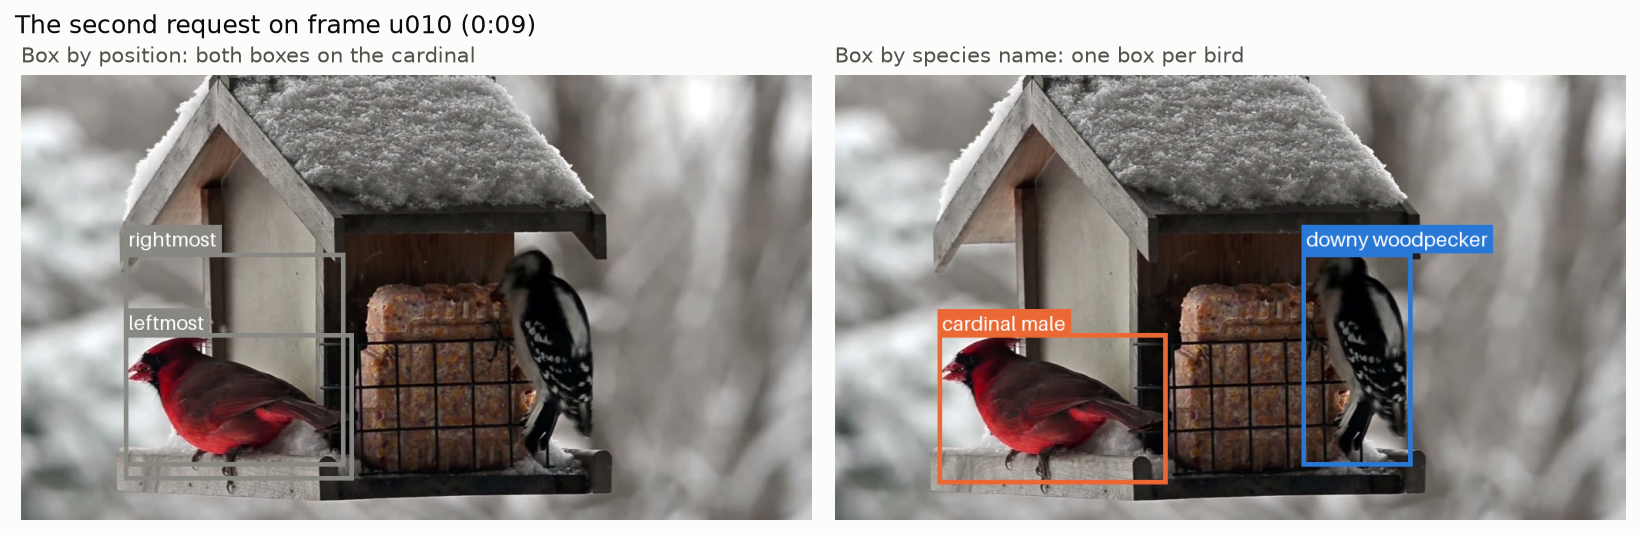

In [ ]:
SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
BLUE, ORANGE = "#2a78d6", "#eb6834"
COLOURS = {"cardinal_male": ORANGE, "downy_woodpecker": BLUE}  # every other species: INK2
FONT = ImageFont.load_default(size=26)


def draw(ax, name: str, boxes: list[tuple[str, dict, str]], title: str) -> None:
    """Draw (label, edges, colour) boxes on a frame and put it on a matplotlib axis."""
    image = PILImage.open(FRAMES / name).convert("RGB")
    width, height = image.size
    pen = ImageDraw.Draw(image)
    for label, e, colour in boxes:
        x0, y0 = e["left"] * width, e["top"] * height
        pen.rectangle([x0, y0, e["right"] * width, e["bottom"] * height], outline=colour, width=6)
        text_box = pen.textbbox((x0, y0), label, font=FONT)
        y = y0 - (text_box[3] - text_box[1]) - 12 if y0 > 40 else y0 + 6
        pen.rectangle([x0, y, x0 + text_box[2] - text_box[0] + 12, y + 36], fill=colour)
        pen.text((x0 + 6, y + 2), label, fill="white", font=FONT)
    ax.imshow(image)
    ax.set_axis_off()
    ax.set_title(title, loc="left", fontsize=10, color=INK2)


def show(fig, filename: str) -> None:
    """Show a figure in a notebook; save it as a PNG when run as a script."""
    if __name__ == "__main__" and "__file__" in globals():
        fig.savefig(filename, dpi=120)
        print(f"saved {filename}")
    else:
        display(fig)
    plt.close(fig)


fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), facecolor=SURFACE)
draw(
    axes[0],
    "u010.jpg",
    [(key, by_position.boxes[key].box.model_dump(), MUTED) for key in POSITION_BOXES],
    "Box by position: both boxes on the cardinal",
)
draw(
    axes[1],
    "u010.jpg",
    [(key.replace("_", " "), a.box.model_dump(), COLOURS[key]) for key, a in by_species.boxes.items()],
    "Box by species name: one box per bird",
)
fig.suptitle("The second request on frame u010 (0:09)", x=0.01, ha="left", color=INK, fontsize=12)
fig.tight_layout()
show(fig, "second-request.png")

A Box question always returns a box. If the first request names a species that is barely in
the frame, such as a bird hidden behind the feeder, the second request still returns a box
for that species, and the box can land on the other bird. Two named boxes that overlap by
0.6 or more are treated as the same bird found twice, and only the box with the higher
confidence is kept. Overlap here is intersection over union: the area the two boxes share,
divided by the total area they cover.

In [ ]:
OVERLAP_AT = 0.6  # two named boxes overlapping this much are one bird found twice


def overlap(a: dict, b: dict) -> float:
    """Intersection over union of two boxes given as edge fractions."""
    w = max(0.0, min(a["right"], b["right"]) - max(a["left"], b["left"]))
    h = max(0.0, min(a["bottom"], b["bottom"]) - max(a["top"], b["top"]))
    area = lambda e: (e["right"] - e["left"]) * (e["bottom"] - e["top"])  # noqa: E731
    union = area(a) + area(b) - w * h
    return w * h / union if union > 0 else 0.0


def dedupe(birds: list[dict]) -> list[dict]:
    kept: list[dict] = []
    for bird in sorted(birds, key=lambda b: -b["box_confidence"]):
        if all(overlap(bird["box"], k["box"]) < OVERLAP_AT for k in kept):
            kept.append(bird)
    return kept

## Ask about every frame

For each frame:

1. Send the five questions. Stop there if `bird_present` is below 0.5, or if neither
   species answer reaches 0.5.
2. If `how_many` is `several` and the two species answers name different species, send the
   second request for one box per species, then run `dedupe()` on the boxes. Do the same
   when only one side's answer reaches 0.5, because the `bird` box might be around the
   other bird.
3. Otherwise, keep the most likely species and the `bird` box from the first request.

The result for a frame is each bird's species, species probability, box and box
confidence, plus the number of requests and the seconds the frame took.

In [ ]:
PRESENT_AT = 0.5  # below this, the frame is empty and the other answers are ignored
SPECIES_AT = 0.5  # a species answer below this is too unsure to name a box


def ask_frame(path: Path) -> dict:
    first, seconds = ask(path, QUESTIONS)
    result = {
        "frame": path.name,
        "bird_present": first.nouls["bird_present"].noul,
        "how_many": first.choices["how_many"].choice,
        "birds": [],
        "requests": 1,
        "seconds": seconds,
    }
    # the species named by the leftmost and rightmost answers, each with its best probability
    named: dict[str, float] = {}
    sure_sides = 0
    for key in ("species_left", "species_right"):
        answer = first.choices[key]
        p = answer.probabilities[answer.choice]
        if p >= SPECIES_AT:
            named[answer.choice] = max(p, named.get(answer.choice, 0.0))
            sure_sides += 1
    if result["bird_present"] < PRESENT_AT or not named:
        return result

    # with several birds, the `bird` box only fits when both sides name the same species
    if result["how_many"] == "several" and (len(named) == 2 or sure_sides < 2):
        second, more_seconds = ask(path, box_questions(list(named)))
        result["requests"] = 2
        result["seconds"] += more_seconds
        boxes = {sp: second.boxes[sp] for sp in named}
    else:
        top = max(named, key=named.get)
        named, boxes = {top: named[top]}, {top: first.boxes["bird"]}

    birds = [
        {"species": sp, "p": p, "box": boxes[sp].box.model_dump(), "box_confidence": boxes[sp].confidence}
        for sp, p in named.items()
    ]
    result["birds"] = dedupe(birds)
    return result

The frames don't depend on each other, so four threads ask about them in parallel. The
results still come back in frame order, because `pool.map` keeps the order of its input. On
a live camera, send one frame at a time instead, each as soon as the previous answer is
back.

In [ ]:
with ThreadPoolExecutor(max_workers=4) as pool:  # 101 frames, about 180 requests, 4 at a time
    results = list(pool.map(ask_frame, paths))

two_requests = [r for r in results if r["requests"] == 2]
print(f"{len(results)} frames, {sum(r['requests'] for r in results)} requests")
print(f"frames that needed the second request: {len(two_requests)}")
print(f"frames that ended with two boxes:      {sum(len(r['birds']) == 2 for r in results)}")
print(f"seconds per frame, median: {statistics.median(r['seconds'] for r in results):.2f}")

101 frames, 178 requests
frames that needed the second request: 77
frames that ended with two boxes:      66
seconds per frame, median: 0.54


Some frames sent the second request and still ended with one box. On those frames, either
only one species answer reached 0.5, or the two named boxes overlapped and `dedupe()` kept
one.

## Turn answers into visits

Visits are built from the results in frame order, one species at a time, so two birds at
the feeder at once make two overlapping visits. Three settings decide what counts as a
visit:

- A frame counts toward a species when that species' probability is at least `species_at`.
- A visit stays open through gaps of up to `max_gap` frames, such as when the bird hops out
  of view for a moment.
- A visit needs at least `min_frames` frames that name its species. With the default of 2,
  a wrong answer on a single frame doesn't become a visit.

These settings belong to your application, and Jev never sees them. To try other values,
rerun `visits()` on the saved results. No new requests are needed.

In [ ]:
def visits(results: list[dict], species_at=0.6, max_gap=2, min_frames=2) -> list[dict]:
    done, open_visits, last_seen = [], {}, {}
    for second, result in enumerate(results):  # one frame per second
        seen = {b["species"] for b in result["birds"] if b["p"] >= species_at}
        for sp in list(open_visits):
            if sp not in seen and second - last_seen[sp] > max_gap:
                done.append(open_visits.pop(sp))
        for sp in sorted(seen):
            if sp in open_visits:
                open_visits[sp]["end"] = second
                open_visits[sp]["frames"] += 1
            else:
                open_visits[sp] = {"species": sp, "start": second, "end": second, "frames": 1}
            last_seen[sp] = second
    done.extend(open_visits.values())
    kept = [v for v in done if v["frames"] >= min_frames]
    return sorted(kept, key=lambda v: (v["start"], v["species"]))


def clock(second: int) -> str:
    return f"{second // 60}:{second % 60:02d}"


def print_visits(found: list[dict]) -> None:
    for v in found:
        seconds = v["end"] - v["start"] + 1
        print(f"  {v['species']:<18}{clock(v['start'])} to {clock(v['end'])}  ({seconds} s)")


found = visits(results)
print("Visits:")
print_visits(found)

per_species: dict[str, list[int]] = {}
for v in found:
    count = per_species.setdefault(v["species"], [0, 0])
    count[0] += 1
    count[1] += v["end"] - v["start"] + 1
print("\nPer species:")
for sp, (n, seconds) in sorted(per_species.items(), key=lambda kv: -kv[1][1]):
    print(f"  {sp:<18}{n} visit{'s' if n > 1 else ''}, {seconds} s at the feeder")
print("\nVisits in the hand labels:")
print_visits(visits([{"birds": [{"species": s, "p": 1.0} for s in labels[n]["species"]]} for n in NAMES]))

Visits:
  cardinal_male     0:00 to 1:02  (63 s)
  downy_woodpecker  0:00 to 1:29  (90 s)
  cardinal_male     1:12 to 1:15  (4 s)

Per species:
  downy_woodpecker  1 visit, 90 s at the feeder
  cardinal_male     2 visits, 67 s at the feeder

Visits in the hand labels:
  cardinal_male     0:00 to 1:02  (63 s)
  downy_woodpecker  0:00 to 1:29  (90 s)


As a timeline, each row of the visit log is a species and each bar is one visit, with the
total time at the feeder beside the row.

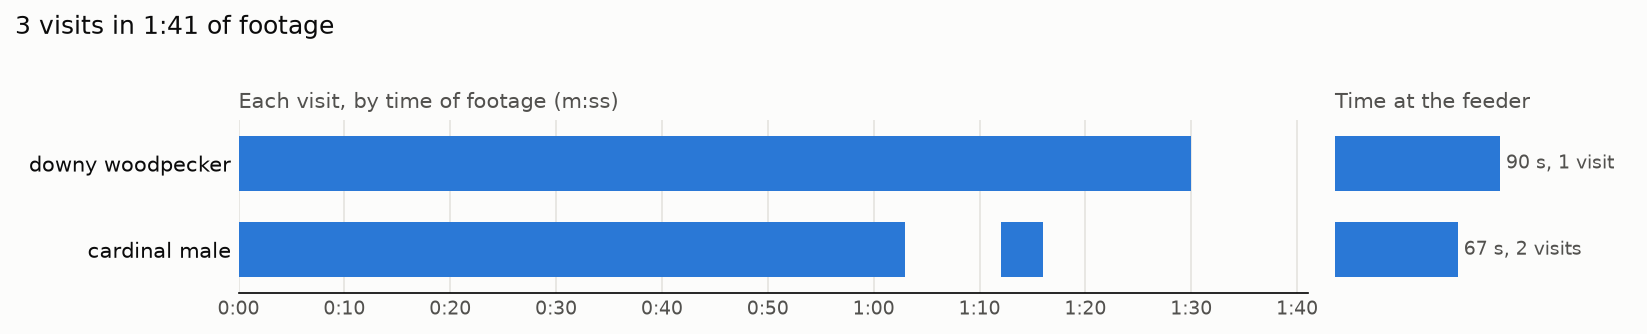

In [ ]:
def draw_visits(found: list[dict], seconds: int, title: str) -> None:
    by_species: dict[str, list[dict]] = {}
    for v in found:
        by_species.setdefault(v["species"], []).append(v)
    total = {sp: sum(v["end"] - v["start"] + 1 for v in vs) for sp, vs in by_species.items()}
    order = sorted(by_species, key=lambda sp: -total[sp])

    height = 0.45 * len(order) + 1.4
    fig, (ax, bx) = plt.subplots(
        1, 2, figsize=(11, height), facecolor=SURFACE,
        gridspec_kw={"width_ratios": [3.6, 1], "wspace": 0.04},
    )
    for a in (ax, bx):
        a.set_facecolor(SURFACE)
        a.spines[["top", "right", "left"]].set_visible(False)
        a.tick_params(colors=INK2, labelsize=9, length=0)
    for row, sp in enumerate(order):
        colour = MUTED if sp == "other" else BLUE
        spans = [(v["start"], v["end"] - v["start"] + 1) for v in by_species[sp]]
        ax.broken_barh(spans, (row - 0.32, 0.64), facecolors=colour)
        bx.barh(row, total[sp], height=0.64, color=colour)
        n = len(by_species[sp])
        label = f"{total[sp]} s, {n} visit{'s' if n > 1 else ''}"
        bx.text(total[sp] + seconds * 0.03, row, label, va="center", fontsize=9, color=INK2)
    ax.set_yticks(range(len(order)), [sp.replace("_", " ") for sp in order], color=INK, fontsize=10)
    ax.set_xlim(0, seconds)
    ax.set_xticks(range(0, seconds + 1, 10), [clock(s) for s in range(0, seconds + 1, 10)])
    ax.grid(axis="x", color="#e4e3df")
    ax.set_axisbelow(True)
    ax.set_title("Each visit, by time of footage (m:ss)", loc="left", fontsize=10, color=INK2)
    bx.set_xlim(0, seconds * 1.6)
    bx.set_xticks([])
    bx.set_yticks([])
    bx.spines["bottom"].set_visible(False)
    bx.set_title("Time at the feeder", loc="left", fontsize=10, color=INK2)
    for a in (ax, bx):
        a.set_ylim(len(order) - 0.5, -0.5)
    fig.suptitle(title, x=0.01, ha="left", fontsize=12, color=INK)
    # margins in inches: the species names on the left, the titles on top, the times below
    fig.subplots_adjust(left=1.6 / 11, right=0.99, top=1 - 0.75 / height, bottom=0.4 / height)
    show(fig, "visits.png")


draw_visits(found, len(results), f"{len(found)} visits in {clock(len(results))} of footage")

The two long visits match the visit log built the same way from our hand labels, with the
same start and end seconds. In every run we made of this clip, the two long visits came out
the same, but the short visits changed from run to run.

The short visit here is wrong: the male cardinal visit from 1:12 to 1:15 is a female
cardinal behind the feeder, misnamed when only her red beak showed.

Lowering `min_frames` to 1 shows the single-frame sightings that the default of 2 keeps out
of the log:

In [ ]:
logged = {(v["species"], v["start"]) for v in visits(results)}
print("Single-frame sightings that min_frames=2 leaves out:")
print_visits([v for v in visits(results, min_frames=1) if (v["species"], v["start"]) not in logged])

Single-frame sightings that min_frames=2 leaves out:
  cardinal_female   1:04 to 1:04  (1 s)
  cardinal_female   1:08 to 1:08  (1 s)
  other             1:16 to 1:16  (1 s)
  cardinal_male     1:34 to 1:34  (1 s)


Some of these are real birds, such as the female cardinal at 1:04 and 1:08, and some are
misreads, such as the male cardinal at 1:34. A higher `min_frames` keeps more wrong answers
out of the log, and it also drops more birds that only show up for a second or two.

## Check the answers against the labels

Two checks compare the answers with the hand labels:

- whether `bird_present` agrees with the label on whether the frame has a bird in it
- whether every labeled bird's species is among the species that `ask_frame()` returned

A frame marked `partial` counts as having a bird for the first check. It is left out of the
second, because its label doesn't name every bird in it.

In [ ]:
present_ok, found, total, misses = 0, 0, 0, []
for r in results:
    label = labels[r["frame"]]
    has_bird = bool(label["species"]) or label["partial"]  # a partial bird is still a bird
    if (r["bird_present"] >= PRESENT_AT) == has_bird:
        present_ok += 1
    else:
        misses.append(f"{r['frame']}  bird_present {r['bird_present']:.2f}, labeled {label['species'] or 'empty'}")
    if label["partial"]:
        continue
    returned = {b["species"] for b in r["birds"]}
    for sp in label["species"]:
        total += 1
        if sp in returned:
            found += 1
        else:
            misses.append(f"{r['frame']}  labeled {sp}, returned {sorted(returned) or 'nothing'}")

print(f"bird_present agrees with the labels: {present_ok}/{len(results)} frames")
print(f"labeled birds returned:              {found}/{total}")
print("\nDisagreements:")
print("\n".join(misses) or "none")

bird_present agrees with the labels: 101/101 frames
labeled birds returned:              132/133

Disagreements:
u063.jpg  labeled downy_woodpecker, returned ['cardinal_male']


The hardest frames for `bird_present` are 1:33 and 1:34, where only part of a cardinal
shows; the left half of the figure below is 1:33. Jev scored both at about 0.8 and counted
the bird, and the labels mark both `partial`.

The one labeled bird that Jev missed is the woodpecker at 1:02, which shares the frame with
the male cardinal. That frame came back with only the male cardinal.

The right half of the figure shows a failure that `dedupe()` doesn't catch. At 1:15, the
female cardinal's beak shows at the right edge of the cage, and Jev named a male cardinal.
The box for the male cardinal landed on the woodpecker. It overlaps the woodpecker's own
box by less than 0.6, so both boxes stay. A check on each box would catch this: crop to the
box and ask a `Noul` question whether the bird in the crop is a male cardinal.

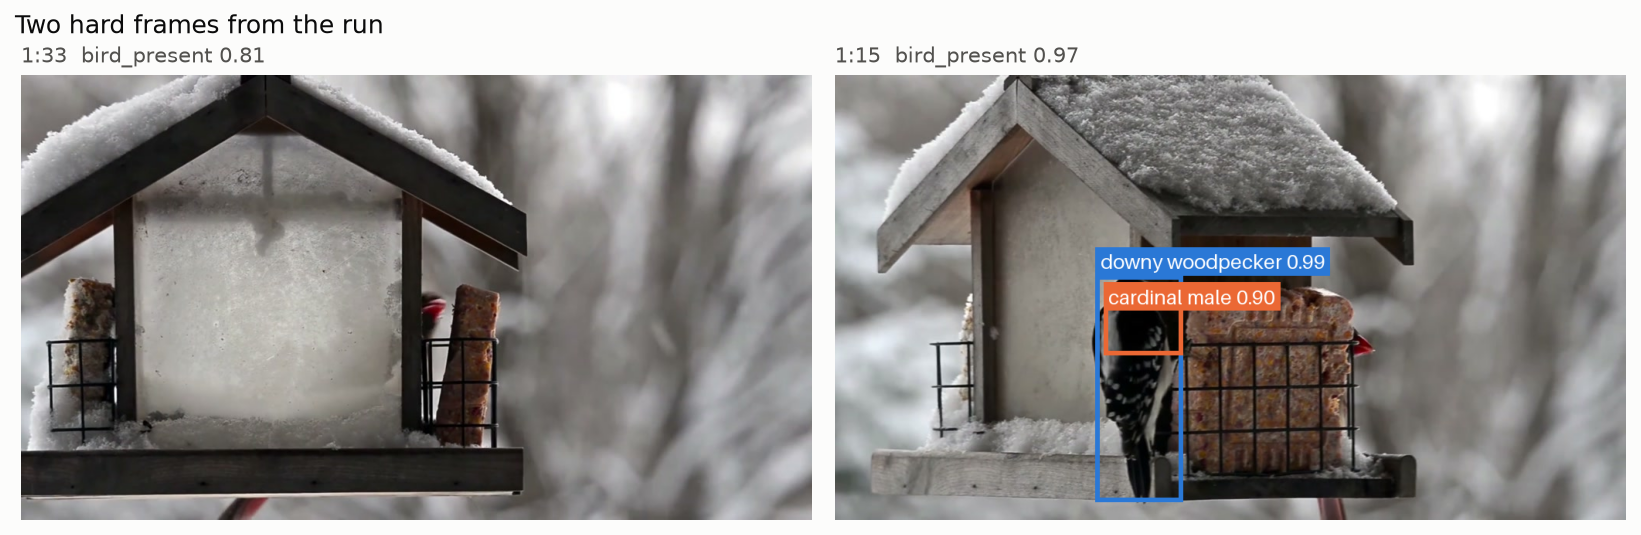

In [ ]:
by_frame = {r["frame"]: r for r in results}


def answer_boxes(name: str) -> list[tuple[str, dict, str]]:
    return [
        (f"{b['species'].replace('_', ' ')} {b['p']:.2f}", b["box"], COLOURS.get(b["species"], INK2))
        for b in by_frame[name]["birds"]
    ]


fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), facecolor=SURFACE)
for ax, name in zip(axes, ("u094.jpg", "u076.jpg")):
    r = by_frame[name]
    second = int(name[1:4]) - 1
    draw(ax, name, answer_boxes(name), f"{clock(second)}  bird_present {r['bird_present']:.2f}")
fig.suptitle("Two hard frames from the run", x=0.01, ha="left", color=INK, fontsize=12)
fig.tight_layout()
show(fig, "failures.png")

## See it running live

The same questions work on live footage. The video below shows a small web app built on
them. It takes a frame from a webcam or a video file, asks Jev,
draws the boxes, and keeps a running visit log. In the video, it plays a stretch of the
Ostdrossel feeder cam that the questions weren't tuned on, at about two answers a second.

<Frame>
  <iframe src="https://player.vimeo.com/video/1237184729"
    title="Feeder watch web app demo"
    className="w-full aspect-video"
    allow="fullscreen; picture-in-picture"></iframe>
</Frame>

Bird footage: [Ostdrossel feeder cam](https://www.youtube.com/watch?v=h6iNvPiyPbI) by
Ostdrossel, licensed [CC BY](https://creativecommons.org/licenses/by/3.0/), shown with
boxes and labels added by the app.

## Before you point it at your own camera

- **One Box question returns one box.** This code boxes at most two birds per frame,
  and only when they are different species. For more species, ask one `Noul` question per
  species, such as "Is there a blue jay in `frame`?", then a named Box for each species
  whose answer comes back high.
- **Two birds of the same species can't be told apart by name.** For a flock, a zero-shot
  detector such as Meta's SAM 3 can find every bird from the text prompt "bird", with no
  training. Jev can then name the species of each cropped bird.
- **Small frames are rejected.** The [Images](/images) page allows 280 to 1568 pixels on
  each side, with at least 78,400 pixels in total (280 × 280).
- **Adjust the thresholds as needed.** The values of `PRESENT_AT`, `SPECIES_AT`,
  `OVERLAP_AT`, and the `visits()` defaults worked here. Label a few minutes of your own
  footage and check them against it.
- **Write the species list for your camera.** Describe what your camera shows of each bird,
  close-ups included. Keep the `other` option, so that a bird your list doesn't name isn't
  forced into one of the names it does have.